# LAB1 - Bài 11 (Online Retail): Đọc, làm sạch và chuyển đổi dữ liệu (bước 1-8)

**Họ tên:** Đinh Công Vinh Quang  
**MSSV:** 6451071061

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

HO_TEN, MSSV = "Đinh Công Vinh Quang", "6451071061"
print(f"{HO_TEN} - {MSSV}")
import time
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

Đinh Công Vinh Quang - 6451071061


In [2]:
# 1. Đọc dữ liệu
df = pd.read_excel("Online_Retail.xlsx")
print("Kích thước ban đầu:", df.shape)

# 2. Cắt ký tự thừa ở Description, xóa dòng không có InvoiceNo, đổi InvoiceNo về chuỗi
df["Description"] = df["Description"].str.strip()
df = df.dropna(axis=0, subset=["InvoiceNo"])
df["InvoiceNo"] = df["InvoiceNo"].astype("str")

# 3. Xóa hóa đơn tín dụng (InvoiceNo chứa 'C')
credit = df[df["InvoiceNo"].str.contains("C")]
df = df[~df["InvoiceNo"].str.contains("C")]
print("Số dòng hóa đơn tín dụng đã xóa:", len(credit), "| còn lại:", len(df))
df.head(10)

Kích thước ban đầu: (541909, 8)


Số dòng hóa đơn tín dụng đã xóa: 9288 | còn lại: 532621


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


Country
United Kingdom    487622
Germany             9042
France              8408
EIRE                7894
Spain               2485
Netherlands         2363
Belgium             2031
Switzerland         1967
Portugal            1501
Australia           1185
dtype: int64


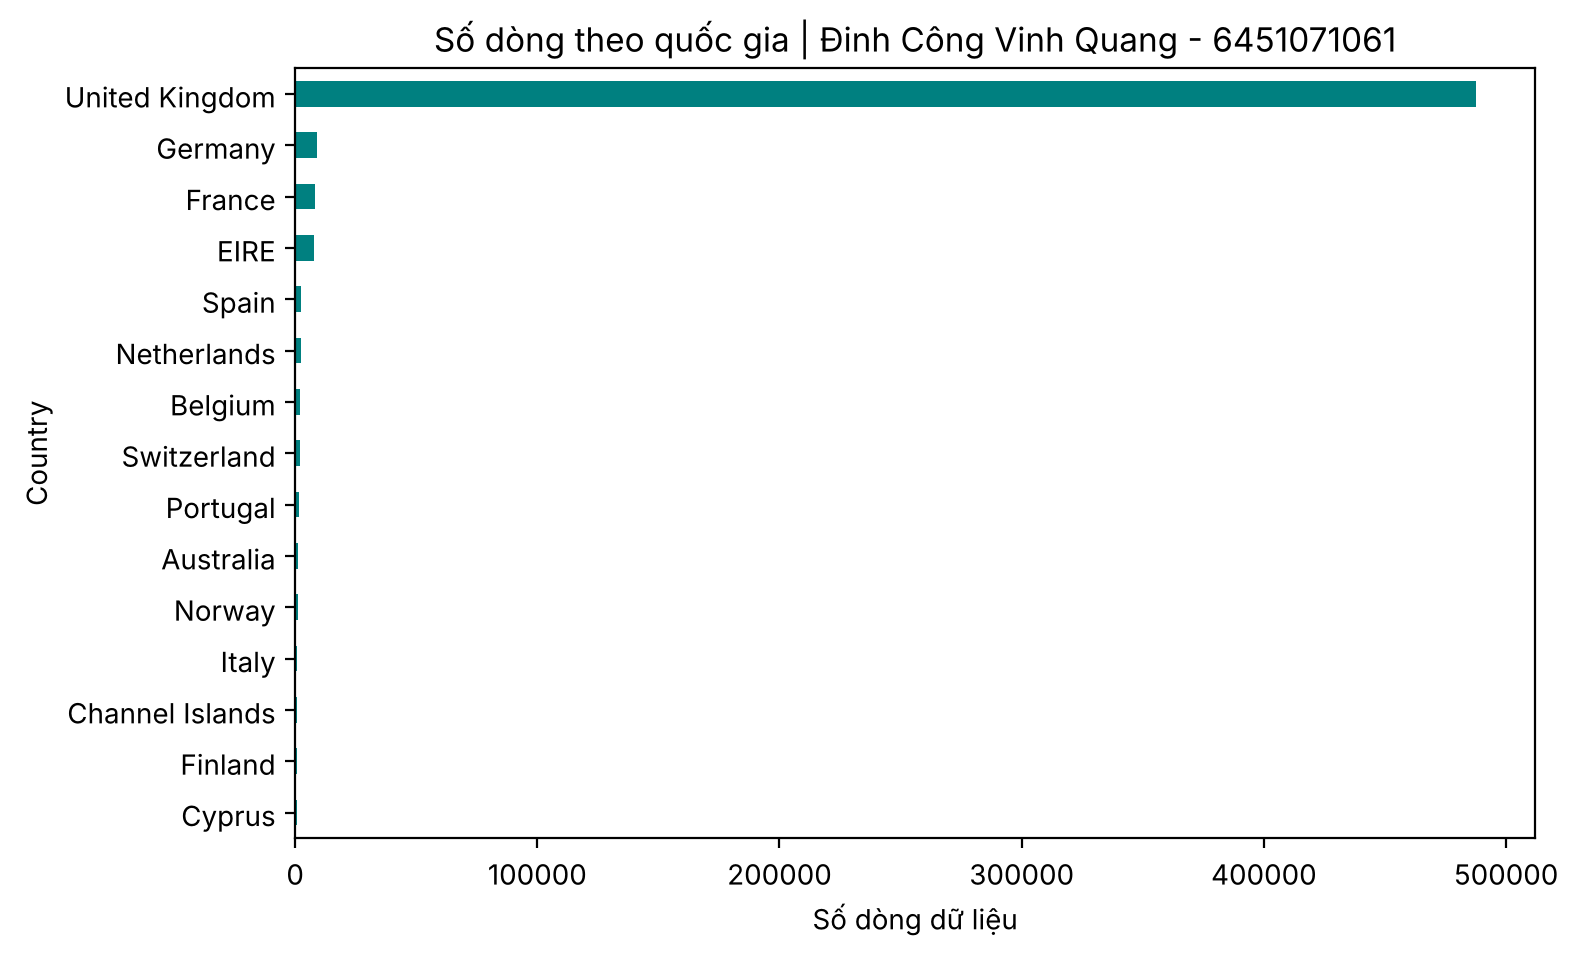

In [3]:
# 4. Thống kê số dòng theo quốc gia
country_counts = df.groupby("Country").size().sort_values(ascending=False)
print(country_counts.head(10))
country_counts.head(15).sort_values().plot(kind="barh", figsize=(8, 5), color="teal")
plt.xlabel("Số dòng dữ liệu"); plt.title(f"Số dòng theo quốc gia | {HO_TEN} - {MSSV}")
plt.show()

In [4]:
# 5. Hóa đơn nước Anh, gom nhóm Quantity theo InvoiceNo và Description
def make_basket(data, country):
    return (data[data["Country"] == country]
            .groupby(["InvoiceNo", "Description"])["Quantity"].sum().unstack(fill_value=0))

# 7. Chuyển về hot/one-hot encoding: Quantity > 0 -> 1 (True), còn lại 0 (False)
def encode_units(x):
    return x > 0

basket = make_basket(df, "United Kingdom")                 # 6. mỗi dòng là một hóa đơn
basket_sets = encode_units(basket)
# 8. Xóa cột POSTAGE (cước phí)
if "POSTAGE" in basket_sets.columns:
    basket_sets = basket_sets.drop(columns=["POSTAGE"])
print("Ma trận hóa đơn x mặt hàng:", basket_sets.shape)
basket.iloc[:5, :6]

Ma trận hóa đơn x mặt hàng: (18667, 4174)


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD
InvoiceNo,,,,,,
536365,0,0,0,0,0,0
536366,0,0,0,0,0,0
536367,0,0,0,0,0,0
536368,0,0,0,0,0,0
536369,0,0,0,0,0,0


In [5]:
basket_sets.iloc[:5, :6]

Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD
InvoiceNo,,,,,,
536365,False,False,False,False,False,False
536366,False,False,False,False,False,False
536367,False,False,False,False,False,False
536368,False,False,False,False,False,False
536369,False,False,False,False,False,False
